# Задание 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('vgsales.csv', encoding='utf-8')

In [3]:
df.head(10)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
5,6,Tetris,GB,1989.0,Puzzle,Nintendo,23.20,2.26,4.22,0.58,30.26
6,7,New Super Mario Bros.,DS,2006.0,Platform,Nintendo,11.38,9.23,6.50,2.90,30.01
7,8,Wii Play,Wii,2006.0,Misc,Nintendo,14.03,9.20,2.93,2.85,29.02
8,9,New Super Mario Bros. Wii,Wii,2009.0,Platform,Nintendo,14.59,7.06,4.70,2.26,28.62
9,10,Duck Hunt,NES,1984.0,Shooter,Nintendo,26.93,0.63,0.28,0.47,28.31


# Задание 2

In [20]:
print(f'Строк: {df.shape[0]}\nСтолбцов: {df.shape[1]}')

Строк: 16598
Столбцов: 11


In [25]:
df.columns.tolist()

['Rank',
 'Name',
 'Platform',
 'Year',
 'Genre',
 'Publisher',
 'NA_Sales',
 'EU_Sales',
 'JP_Sales',
 'Other_Sales',
 'Global_Sales']

In [26]:
df.dtypes

,0
Rank,int64
Name,object
Platform,object
Year,float64
Genre,object
Publisher,object
NA_Sales,float64
EU_Sales,float64
JP_Sales,float64
Other_Sales,float64


In [27]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [33]:
df.select_dtypes(include='number').columns

Index(['Rank', 'Year', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales',
       'Global_Sales'],
      dtype='object')

In [38]:
df.select_dtypes(include='object').columns

Index(['Name', 'Platform', 'Genre', 'Publisher'], dtype='object')

In [39]:
df['Global_Sales'].dtype

dtype('float64')

# Задание 3

In [54]:
missing = df.isnull().sum()
missing[missing != 0].index.tolist()

['Year', 'Publisher']

In [56]:
missing[missing != 0]

,0
Year,271
Publisher,58


In [63]:
missing.sort_values(ascending=False).iloc[[0]]

,0
Year,271


In [68]:
df[df['Year'].isnull()]

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
179,180,Madden NFL 2004,PS2,NaN,Sports,Electronic Arts,4.26,0.26,0.01,0.71,5.23
377,378,FIFA Soccer 2004,PS2,NaN,Sports,Electronic Arts,0.59,2.36,0.04,0.51,3.49
431,432,LEGO Batman: The Videogame,Wii,NaN,Action,Warner Bros. Interactive Entertainment,1.86,1.02,0.00,0.29,3.17
470,471,wwe Smackdown vs. Raw 2006,PS2,NaN,Fighting,NaN,1.57,1.02,0.00,0.41,3.00
607,608,Space Invaders,2600,NaN,Shooter,Atari,2.36,0.14,0.00,0.03,2.53
...,...,...,...,...,...,...,...,...,...,...,...
16307,16310,Freaky Flyers,GC,NaN,Racing,Unknown,0.01,0.00,0.00,0.00,0.01
16327,16330,Inversion,PC,NaN,Shooter,Namco Bandai Games,0.01,0.00,0.00,0.00,0.01
16366,16369,Hakuouki: Shinsengumi Kitan,PS3,NaN,Adventure,Unknown,0.01,0.00,0.00,0.00,0.01
16427,16430,Virtua Quest,GC,NaN,Role-Playing,Unknown,0.01,0.00,0.00,0.00,0.01


# Задание 4

In [73]:
df_clean_year = df.dropna(subset=['Year'])

In [77]:
df_clean_year.shape

(16327, 11)

In [74]:
df_clean_year.isnull().sum()

,0
Rank,0
Name,0
Platform,0
Year,0
Genre,0
Publisher,36
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0


**Вопросы.**

●	сколько строк было в исходном датасете?

16598 строк

●	сколько строк осталось после удаления пропусков Year?

16327 строк

●	почему, по вашему мнению, пропуски в Year могут мешать анализу игр по годам?

Мешает тем, что буквально выпадает пласт игр, которые могли быть проанализированы

In [123]:
df_clean_year['Genre'].unique().tolist()

['Sports',
 'Platform',
 'Racing',
 'Role-Playing',
 'Puzzle',
 'Misc',
 'Shooter',
 'Simulation',
 'Action',
 'Fighting',
 'Adventure',
 'Strategy']

In [124]:
df_clean_year['Genre'].nunique()

12

In [125]:
df_clean_year['Platform'].unique().tolist()

['Wii',
 'NES',
 'GB',
 'DS',
 'X360',
 'PS3',
 'PS2',
 'SNES',
 'GBA',
 '3DS',
 'PS4',
 'N64',
 'PS',
 'XB',
 'PC',
 '2600',
 'PSP',
 'XOne',
 'GC',
 'WiiU',
 'GEN',
 'DC',
 'PSV',
 'SAT',
 'SCD',
 'WS',
 'NG',
 'TG16',
 '3DO',
 'GG',
 'PCFX']

In [126]:
df_clean_year['Platform'].nunique()

31

In [127]:
df_clean_year['Publisher'].value_counts()

,count
Publisher,
Electronic Arts,1339
Activision,966
Namco Bandai Games,928
Ubisoft,918
Konami Digital Entertainment,823
...,...
King Records,1
Graphsim Entertainment,1
Takuyo,1


**Вопросы**

●	сколько жанров представлено?

Представлено 12 жанров

●	сколько платформ?

31 платформ

●	сколько издателей?

576 издателей

●	какой из этих признаков имеет больше всего уникальных значений?

Столбец издетелей имеет больше всего уникальных значений

# Задание 6

In [122]:
genre_count = df_clean_year.groupby('Genre')['Name'].count()
genre_count

,Name
Genre,
Action,3253
Adventure,1276
Fighting,836
Misc,1710
Platform,876
Puzzle,571
Racing,1226
Role-Playing,1471
Shooter,1282


In [87]:
genre_count.sort_values(ascending=False)

,Name
Genre,
Action,3253
Sports,2304
Misc,1710
Role-Playing,1471
Shooter,1282
Adventure,1276
Racing,1226
Platform,876
Simulation,851


# Задание 7

In [128]:
genre_sales = df_clean_year.groupby('Genre')['Global_Sales'].sum()
genre_sales

,Global_Sales
Genre,
Action,1722.88
Adventure,234.80
Fighting,444.05
Misc,797.62
Platform,829.15
Puzzle,242.22
Racing,726.77
Role-Playing,923.84
Shooter,1026.20


In [90]:
genre_sales.sort_values(ascending=False)

,Global_Sales
Genre,
Action,1751.18
Sports,1330.93
Shooter,1037.37
Role-Playing,927.37
Platform,831.37
Misc,809.96
Racing,732.04
Fighting,448.91
Simulation,392.20


# Задание 8

In [129]:
df_clean_year.sort_values('Global_Sales', ascending=False).head(10)[['Rank', 'Name', 'Platform', 'Genre', 'Global_Sales']]

,Rank,Name,Platform,Genre,Global_Sales
0,1,Wii Sports,Wii,Sports,82.74
1,2,Super Mario Bros.,NES,Platform,40.24
2,3,Mario Kart Wii,Wii,Racing,35.82
3,4,Wii Sports Resort,Wii,Sports,33.00
4,5,Pokemon Red/Pokemon Blue,GB,Role-Playing,31.37
5,6,Tetris,GB,Puzzle,30.26
6,7,New Super Mario Bros.,DS,Platform,30.01
7,8,Wii Play,Wii,Misc,29.02
8,9,New Super Mario Bros. Wii,Wii,Platform,28.62
9,10,Duck Hunt,NES,Shooter,28.31


# Задание 9

In [130]:
games_by_platform = df_clean_year['Platform'].value_counts()
games_by_platform

,count
Platform,
DS,2133
PS2,2127
PS3,1304
Wii,1290
X360,1235
PSP,1197
PS,1189
PC,943
GBA,811


In [102]:
games_by_platform.sort_values(ascending=False).head(10)

,count
Platform,
DS,2163
PS2,2161
PS3,1329
Wii,1325
X360,1265
PSP,1213
PS,1196
PC,960
XB,824


In [131]:
df_clean_year.groupby('Platform')['Global_Sales'].sum().sort_values(ascending=False).head(10)

,Global_Sales
Platform,
PS2,1233.46
X360,969.61
PS3,949.35
Wii,909.81
DS,818.96
PS,727.39
GBA,313.56
PSP,291.71
PS4,278.10


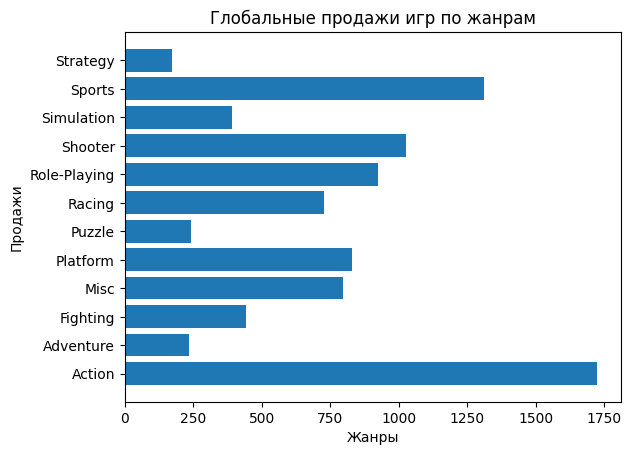

In [132]:
games_by_genres = df_clean_year.groupby('Genre')['Global_Sales'].sum()

plt.barh(games_by_genres.index, games_by_genres.values)
plt.xlabel('Жанры')
plt.ylabel('Продажи')
plt.title('Глобальные продажи игр по жанрам')

plt.show()

**Вопросы**

●	какие жанры имеют наибольшие продажи?

Action и Sports

●	какие жанры имеют наименьшие продажи?

Strategy, Simulation, Puzzle, Fighting, Adventure

●	насколько сильно отличаются значения?

наибольшие и наименьшие продажи - разительно. Как минимум на тысячу продаж


# Задание 11

In [133]:
df_clean_year[['NA_Sales', 'Global_Sales']].corr()

,NA_Sales,Global_Sales
NA_Sales,1.000000,0.941268
Global_Sales,0.941268,1.000000


**Вопросы**

●	получилось положительное или отрицательное значение?

Положительное

●	близко ли оно к 1?

Да, близко

●	можно ли говорить о выраженной положительной взаимосвязи между NA_Sales и Global_Sales?

Я бы сказал да

Text(0, 0.5, 'Продажи по миру')

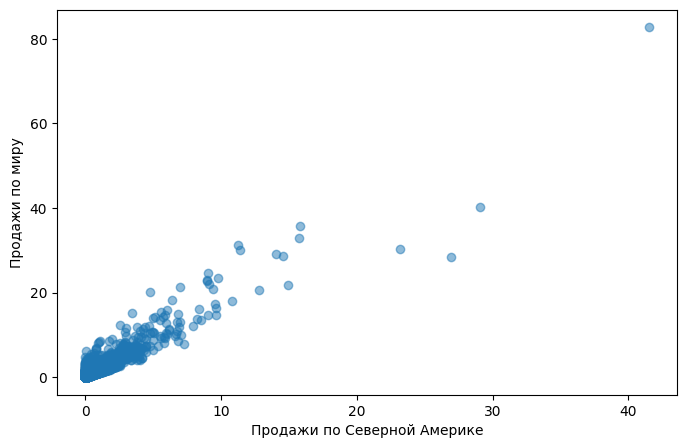

In [140]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df_clean_year['NA_Sales'],
    df_clean_year['Global_Sales'],
    alpha=0.5
)

plt.xlabel('Продажи по Северной Америке')
plt.ylabel('Продажи по миру')

**Вопросы**

●	что обозначает одна точка на графике?

Игру, расположенная по координатам заданой по продаж по СА и миру

●	наблюдается ли восходящая тенденция?

Я бы сказал да

●	соответствует ли график результату корреляционного анализа?

Думаю да, хотя заметил три особено выбивающихся исключений, которые чаще продавались в СА, чем во всем мире взятом

In [138]:
df_clean_year[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']].corr()

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
NA_Sales,1.000000,0.768936,0.451285,0.634508
EU_Sales,0.768936,1.000000,0.436414,0.726266
JP_Sales,0.451285,0.436414,1.000000,0.290653
Other_Sales,0.634508,0.726266,0.290653,1.000000


**Вывод**

Неполноценные данные могут плохо влиять на общую картину, так что лучше от них избавляться. Игры, которые покупают в азиатской Японии чаще другие, чем в западных Европе и Северной Америке. Некоторые жанры бывают более массовыми чем остальные, в то же время есть мало популярные жанры.